# Lezione 6 — Segnatura IR, termografia e materiali adattivi

Modulo *Radiazione termica e segnatura IR* (Master OQI, prof. R. Li Voti).

Si chiude il cerchio. Una termocamera non misura la temperatura vera:
misura una radianza e la converte in temperatura apparente con un'\(\varepsilon\)
impostata. Invertendo quella conversione, con la temperatura vera letta da
una termocoppia, si ottiene l'emissività del campione. È la procedura usata
a lezione su polveri di VO₂, tessuti e ossidi.

Il biossido di vanadio è il materiale adattivo del corso: a circa 68 °C
passa da semiconduttore a metallo e la sua emissività infrarossa crolla.
Abbassare \(\varepsilon\), a parità di temperatura vera, abbassa la temperatura
che vede la camera. Questa differenza è la segnatura.

I numeri sperimentali riportati sotto sono quelli mostrati a lezione
(polveri di VO₂ e tessuti con polveri bioceramiche). Le costanti ottiche
del modello a multistrato sono valori didattici, scelti per illustrare il
passaggio semiconduttore/metallo: non sono un fit degli spettri FTIR del corso.


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.4, 4.7),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.unicode_minus": False,
})
np.set_printoptions(precision=4, suppress=True)
print("Ambiente pronto.")

from scipy import constants

SIGMA = constants.sigma
H, C, K_B = constants.h, constants.c, constants.k

def planck(lam, T):
    lam = np.asarray(lam, dtype=float)
    x = H * C / (lam * K_B * T)
    out = np.zeros_like(x)
    ok = (x > 0) & (x < 700)
    out[ok] = 2 * np.pi * H * C**2 / lam[ok]**5 / np.expm1(x[ok])
    return out


Ambiente pronto.


## 1. Finestre atmosferiche e rivelatori

Fra la scena e la camera c'è l'aria. Trasmette bene nel visibile, in una
finestra nel medio IR (circa 3–5 μm) e in una nel lontano IR (circa 8–12 μm);
altrove, soprattutto per il vapor d'acqua, assorbe. Lo schema qui sotto è
qualitativo: disegna le finestre di cui parla la lezione, non uno spettro
da trasferimento radiativo.

Su quelle finestre si appoggiano i rivelatori citati a lezione:

- fotoconduttori IR, risposta fra circa 2 e 11 μm;
- fotovoltaici IR, fra circa 3 e 8 μm, anche su raffreddamento termoelettrico a due stadi;
- microbolometri non raffreddati (a-Si, VOx), la scelta delle termocamere
  compatte in LWIR: la radiazione scalda una membranella e ne cambia la resistenza.


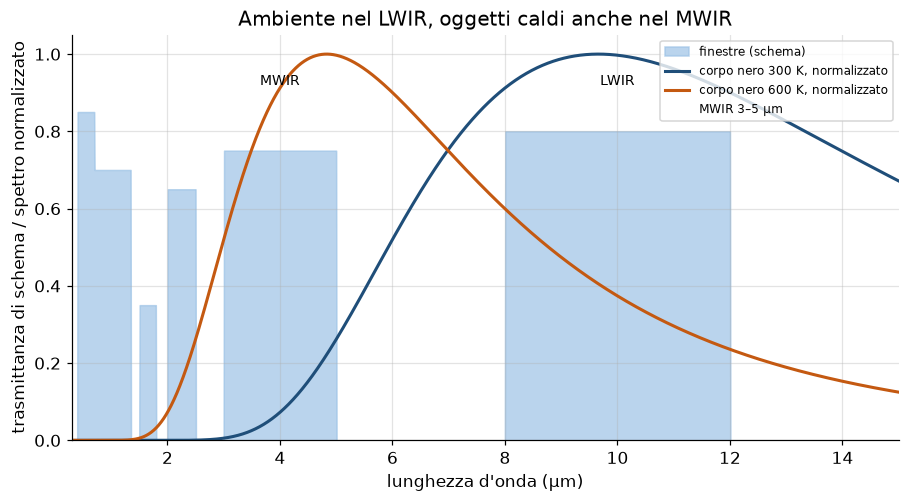

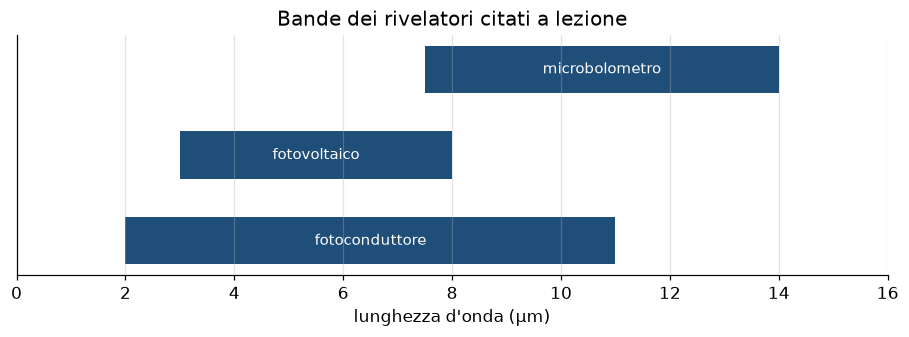

In [2]:
def trasmittanza_schema(lam_um):
    """Schema a gradini delle finestre. Non è uno spettro atmosferico reale."""
    t = np.zeros_like(lam_um, dtype=float)
    intervalli = [
        (0.40, 0.70, 0.85),
        (0.70, 1.35, 0.70),
        (1.50, 1.80, 0.35),
        (2.00, 2.50, 0.65),
        (3.00, 5.00, 0.75),   # MWIR
        (8.00, 12.0, 0.80),   # LWIR
    ]
    for a, b, val in intervalli:
        t[(lam_um >= a) & (lam_um <= b)] = val
    return t

lam_um = np.linspace(0.3, 15.0, 2000)
T_amb, T_hot = 300.0, 600.0
# Spettri normalizzati, per confrontarli con le finestre sulla stessa figura.
def spettro_norm(T):
    s = planck(lam_um * 1e-6, T)
    return s / s.max()

fig, ax = plt.subplots()
ax.fill_between(lam_um, trasmittanza_schema(lam_um), color="#9dc3e6", alpha=0.7, label="finestre (schema)")
ax.plot(lam_um, spettro_norm(T_amb), color="#1f4e79", lw=2, label="corpo nero 300 K, normalizzato")
ax.plot(lam_um, spettro_norm(T_hot), color="#c45911", lw=2, label="corpo nero 600 K, normalizzato")
ax.axvspan(3, 5, color="none", label="MWIR 3–5 μm")
ax.annotate("MWIR", xy=(4.0, 0.92), ha="center", fontsize=9)
ax.annotate("LWIR", xy=(10.0, 0.92), ha="center", fontsize=9)
ax.set_xlim(0.3, 15)
ax.set_ylim(0, 1.05)
ax.set_xlabel("lunghezza d'onda (μm)")
ax.set_ylabel("trasmittanza di schema / spettro normalizzato")
ax.set_title("Ambiente nel LWIR, oggetti caldi anche nel MWIR")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

rivelatori = [
    ("fotoconduttore", 2.0, 11.0),
    ("fotovoltaico", 3.0, 8.0),
    ("microbolometro", 7.5, 14.0),
]
fig, ax = plt.subplots(figsize=(8.4, 3.2))
for i, (nome, a, b) in enumerate(rivelatori):
    ax.barh(i, b - a, left=a, height=0.55, color="#1f4e79")
    ax.text((a + b) / 2, i, nome, ha="center", va="center", color="white", fontsize=10)
ax.set_yticks([])
ax.set_xlabel("lunghezza d'onda (μm)")
ax.set_xlim(0, 16)
ax.set_title("Bande dei rivelatori citati a lezione")
fig.tight_layout()
plt.show()


## 2. Dalla temperatura apparente all'emissività

Sul cammino corto di un banco di misura l'atmosfera si può prendere
trasparente (\(\tau\approx 1\)). La radianza che arriva alla camera è la somma
di quella emessa dal campione e di quella ambientale riflessa:

\[
\varepsilon_s T_s^4 + (1-\varepsilon_s)\,T_\mathrm{amb}^4
= \varepsilon_a T_a^4 + (1-\varepsilon_a)\,T_\mathrm{amb}^4.
\]

\(T_s\) è la temperatura vera (termocoppia), \(T_a\) è la temperatura apparente
che la camera calcola imponendo \(\varepsilon_a\) (a lezione \(\varepsilon_a=0{,}95\)),
\(T_\mathrm{amb}\) è la temperatura dell'ambiente riflesso. Si ricava

\[
\varepsilon_s = \varepsilon_a\,\frac{T_a^4-T_\mathrm{amb}^4}{T_s^4-T_\mathrm{amb}^4}.
\]

La \(T^4\) è l'approssimazione a banda larga usata nella procedura della lezione.
Una camera reale integra una banda con la propria risposta spettrale: la
formula resta la stessa struttura, con la radianza in banda al posto di \(\sigma T^4\).


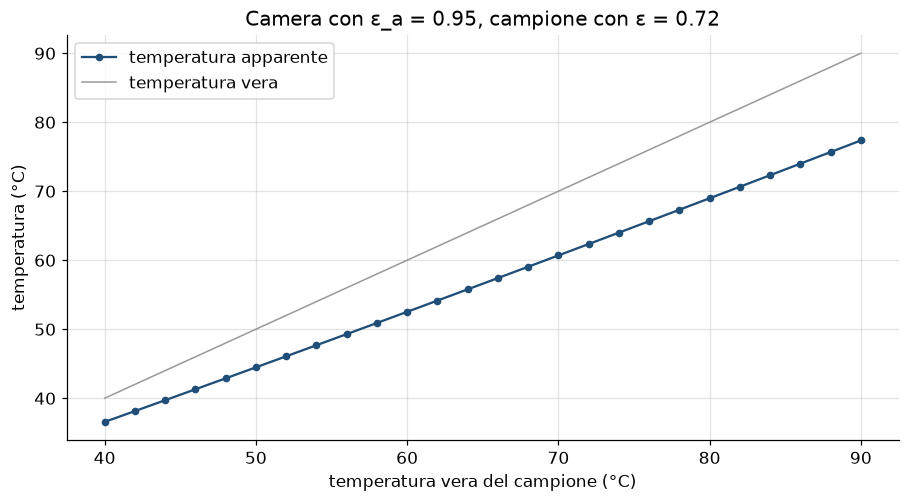

A 60 °C la camera legge 52.52 °C.
Emissività ricostruita (media) = 0.7200
Stima senza termine riflesso, a 60 °C = 0.868
Il termine riflesso non è una correzione piccola: va tenuto.


In [3]:
def epsilon_da_camera(Ta, Ts, Tamb, eps_a=0.95):
    """Emissività del campione a partire dalla temperatura apparente."""
    return eps_a * (Ta**4 - Tamb**4) / (Ts**4 - Tamb**4)

def temperatura_apparente(Ts, eps_s, Tamb, eps_a=0.95):
    """Inverso: ciò che la camera dichiarerebbe."""
    Ta4 = (eps_s * (Ts**4 - Tamb**4)) / eps_a + Tamb**4
    return Ta4 ** 0.25

# Protocollo della lezione: da 40 a 90 °C a passi di 2 °C, andata e ritorno.
Tamb = 25 + 273.15
eps_a = 0.95
eps_vera = 0.72
Ts_C = np.arange(40.0, 90.0 + 1e-9, 2.0)
Ts = Ts_C + 273.15
Ta = temperatura_apparente(Ts, eps_vera, Tamb, eps_a)
eps_ricavata = epsilon_da_camera(Ta, Ts, Tamb, eps_a)

assert np.allclose(eps_ricavata, eps_vera, atol=1e-12)

# Errore se si dimentica il termine riflesso e si fa ε ≈ ε_a (Ta/Ts)^4.
eps_naive = eps_a * (Ta / Ts) ** 4

fig, ax = plt.subplots()
ax.plot(Ts_C, Ta - 273.15, "o-", color="#1f4e79", ms=4, label="temperatura apparente")
ax.plot(Ts_C, Ts_C, color="0.6", lw=1, label="temperatura vera")
ax.set_xlabel("temperatura vera del campione (°C)")
ax.set_ylabel("temperatura (°C)")
ax.set_title(f"Camera con ε_a = {eps_a}, campione con ε = {eps_vera}")
ax.legend()
fig.tight_layout()
plt.show()

print(f"A 60 °C la camera legge {Ta[np.where(Ts_C==60)[0][0]]-273.15:.2f} °C.")
print(f"Emissività ricostruita (media) = {eps_ricavata.mean():.4f}")
print(f"Stima senza termine riflesso, a 60 °C = {eps_naive[np.where(Ts_C==60)[0][0]]:.3f}")
print("Il termine riflesso non è una correzione piccola: va tenuto.")


## 3. Segnatura: stessa temperatura, emissività diversa

La camera, se impostata come corpo nero, attribuisce a un oggetto freddo
in apparenza una temperatura

\[
T_a = \big(\varepsilon\, T_s^4 + (1-\varepsilon)\,T_\mathrm{amb}^4\big)^{1/4}.
\]

Scendere da \(\varepsilon=0{,}9\) a \(\varepsilon=0{,}3\), tenendo l'oggetto a 50 °C
davanti a un ambiente a 20 °C, cancella gran parte del contrasto. È il
meccanismo del mimetismo infrarosso con un materiale adattivo: non si
raffredda l'oggetto, si cambia ciò che emette.


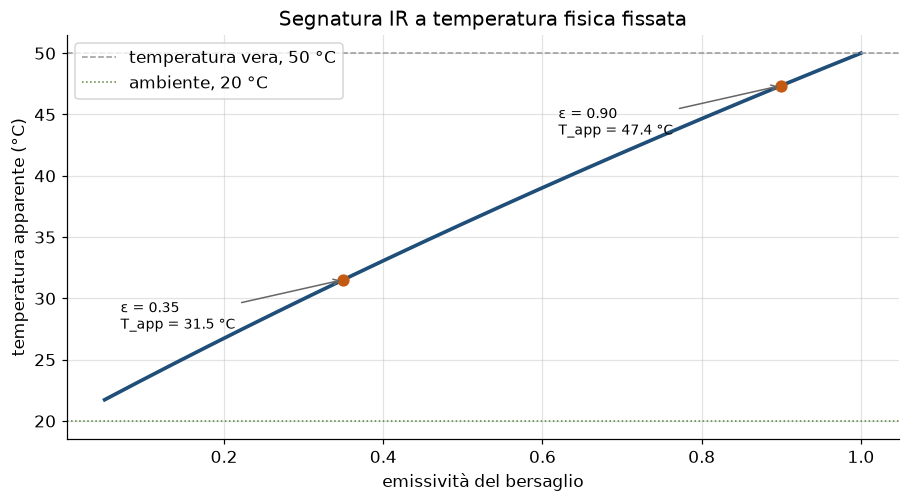

Contrasto apparente rispetto ai 20 °C:
  ε = 0,90 → 27.4 K
  ε = 0,35 → 11.5 K


In [4]:
Ts = 50 + 273.15
Tamb = 20 + 273.15
eps = np.linspace(0.05, 1.0, 200)
Ta = (eps * Ts**4 + (1 - eps) * Tamb**4) ** 0.25

fig, ax = plt.subplots()
ax.plot(eps, Ta - 273.15, color="#1f4e79", lw=2.4)
ax.axhline(50, color="0.6", ls="--", lw=1, label="temperatura vera, 50 °C")
ax.axhline(20, color="#548235", ls=":", lw=1, label="ambiente, 20 °C")
for e_mark in (0.90, 0.35):
    Ta_m = (e_mark * Ts**4 + (1 - e_mark) * Tamb**4) ** 0.25
    ax.plot(e_mark, Ta_m - 273.15, "o", color="#c45911", ms=7)
    ax.annotate(f"ε = {e_mark:.2f}\nT_app = {Ta_m-273.15:.1f} °C",
                xy=(e_mark, Ta_m - 273.15),
                xytext=(e_mark - 0.28, Ta_m - 273.15 - 4),
                fontsize=9, arrowprops=dict(arrowstyle="->", color="0.4"))
ax.set_xlabel("emissività del bersaglio")
ax.set_ylabel("temperatura apparente (°C)")
ax.set_title("Segnatura IR a temperatura fisica fissata")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

Ta_alto = (0.90 * Ts**4 + 0.10 * Tamb**4) ** 0.25 - 273.15
Ta_basso = (0.35 * Ts**4 + 0.65 * Tamb**4) ** 0.25 - 273.15
print(f"Contrasto apparente rispetto ai 20 °C:")
print(f"  ε = 0,90 → {Ta_alto-20:.1f} K")
print(f"  ε = 0,35 → {Ta_basso-20:.1f} K")


## 4. Biossido di vanadio

Il VO₂ cambia reticolo, da monoclino a tetragonale, a \(T_c=68^\circ\mathrm{C}\)
(341 K). In infrarosso passa da uno stato semiconduttore, più emissivo, a uno
stato metallico, più riflettente. Il drogaggio con tungsteno, come ricordato
a lezione, sposta la transizione verso i 30 °C.

I cicli di riscaldamento e raffreddamento non si sovrappongono: c'è isteresi.
I valori medi mostrati a lezione, per polveri pressate e poi trattate in forno,
sono questi.

| campione | ε a freddo | ε a caldo | Δε |
|---|---:|---:|---:|
| P | 0,87 | 0,85 | −0,02 |
| D4 | 0,79 | 0,63 | −0,16 |
| D4T3 | 0,72 | 0,35 | −0,37 |
| D5 | 0,82 | 0,70 | −0,12 |
| D5T5 | 0,68 | 0,26 | −0,42 |

P, il riferimento, quasi non si muove. I trattamenti termici aprono una
finestra di tunabilità fino a circa 0,4.


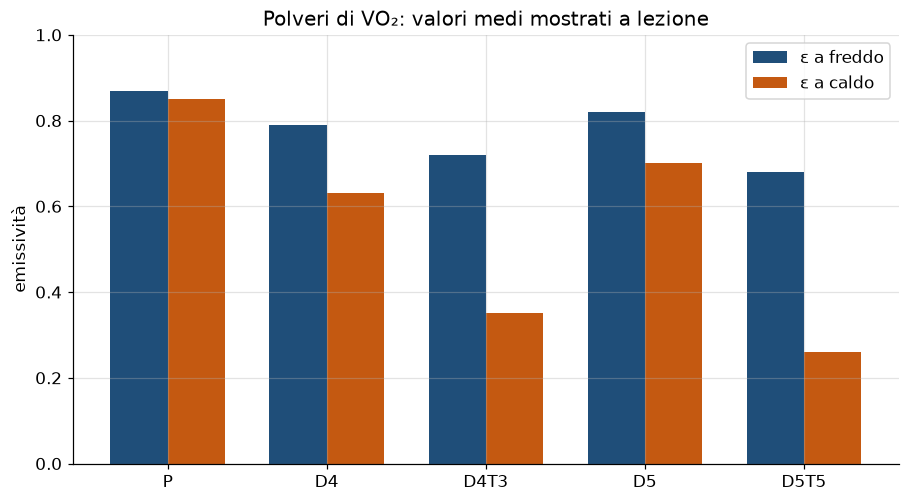

Tunabilità Δε, dalla più grande:
  D5T5   -0.42
  D4T3   -0.37
  D4     -0.16
  D5     -0.12
  P      -0.02


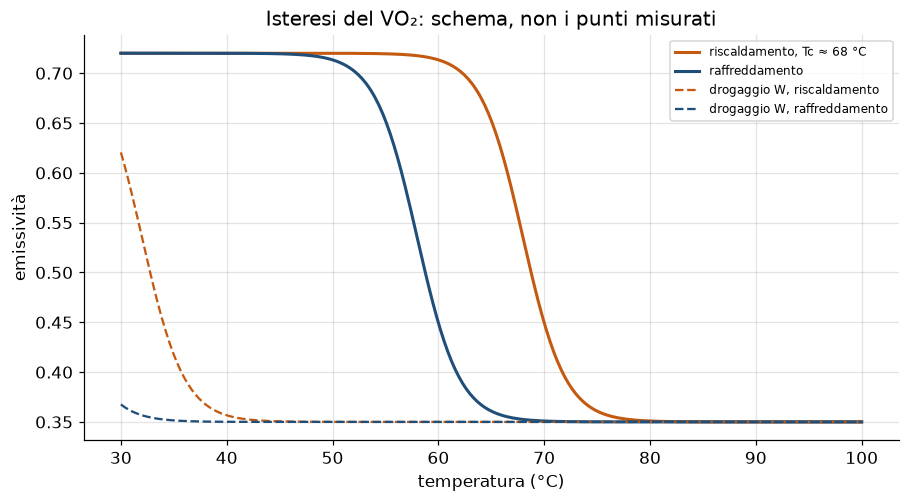

In [5]:
campioni = ["P", "D4", "D4T3", "D5", "D5T5"]
eps_freddo = np.array([0.87, 0.79, 0.72, 0.82, 0.68])
eps_caldo = np.array([0.85, 0.63, 0.35, 0.70, 0.26])
delta = eps_caldo - eps_freddo

fig, ax = plt.subplots()
x = np.arange(len(campioni))
ax.bar(x - 0.18, eps_freddo, width=0.36, label="ε a freddo", color="#1f4e79")
ax.bar(x + 0.18, eps_caldo, width=0.36, label="ε a caldo", color="#c45911")
ax.set_xticks(x, campioni)
ax.set_ylabel("emissività")
ax.set_ylim(0, 1)
ax.set_title("Polveri di VO₂: valori medi mostrati a lezione")
ax.legend()
fig.tight_layout()
plt.show()

ordine = np.argsort(delta)   # il più negativo è la tunabilità maggiore
print("Tunabilità Δε, dalla più grande:")
for i in ordine:
    print(f"  {campioni[i]:6} {delta[i]:+.2f}")


def isteresi_vo2(T_C, Tc_up=68.0, Tc_down=58.0, larghezza=2.0, eps_semi=0.72, eps_met=0.35):
    """Curva didattica. I Tc riproducono l'ordine di grandezza del D4T3, non un fit."""
    salita = eps_met + (eps_semi - eps_met) / (1 + np.exp((T_C - Tc_up) / larghezza))
    discesa = eps_met + (eps_semi - eps_met) / (1 + np.exp((T_C - Tc_down) / larghezza))
    return salita, discesa

T = np.linspace(30, 100, 400)
salita, discesa = isteresi_vo2(T)
# Stesso modello con la transizione spostata dal drogaggio con W, verso ~30 °C.
salita_W, discesa_W = isteresi_vo2(T, Tc_up=32.0, Tc_down=24.0)

fig, ax = plt.subplots()
ax.plot(T, salita, color="#c45911", lw=2, label="riscaldamento, Tc ≈ 68 °C")
ax.plot(T, discesa, color="#1f4e79", lw=2, label="raffreddamento")
ax.plot(T, salita_W, color="#c45911", lw=1.5, ls="--", label="drogaggio W, riscaldamento")
ax.plot(T, discesa_W, color="#1f4e79", lw=1.5, ls="--", label="drogaggio W, raffreddamento")
ax.set_xlabel("temperatura (°C)")
ax.set_ylabel("emissività")
ax.set_title("Isteresi del VO₂: schema, non i punti misurati")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 5. Un film che cambia emissività

Per un corpo opaco \(\varepsilon_\lambda=1-\rho_\lambda\). Un film di 190 nm — lo
spessore del campione A di VO₂ su substrato discusso a lezione — si tratta
con la matrice di trasferimento, a incidenza normale. Il substrato di questo
conto è alluminio, opaco: così \(\varepsilon=1-R\) senza il canale di trasmissione
di un wafer di silicio.

Costanti ottiche **didattiche**, costanti in lunghezza d'onda, abbastanza
realistiche da separare i due stati nel medio e lontano IR:

- semiconduttore: \(n=2{,}8+0{,}3\,i\)
- metallo: \(n=5+6\,i\)
- alluminio: \(n=8+40\,i\)

Durante la transizione i due stati coesistono. L'effective medium di
Maxwell-Garnett, con inclusione metallica di frazione \(f\) in matrice
semiconduttrice, è la formula nominata a lezione:

\[
\varepsilon_\mathrm{eff}
=\varepsilon_h\frac{\varepsilon_i+2\varepsilon_h+2f(\varepsilon_i-\varepsilon_h)}
{\varepsilon_i+2\varepsilon_h-f(\varepsilon_i-\varepsilon_h)}.
\]


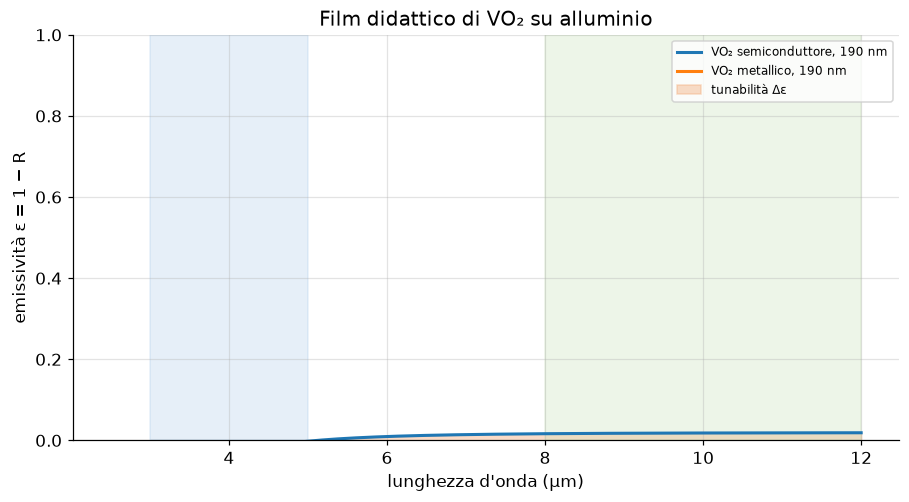

Emissività media del modello:
  3–5 μm   semi -0.06   metallo -0.39
  8–12 μm  semi 0.02   metallo -0.05


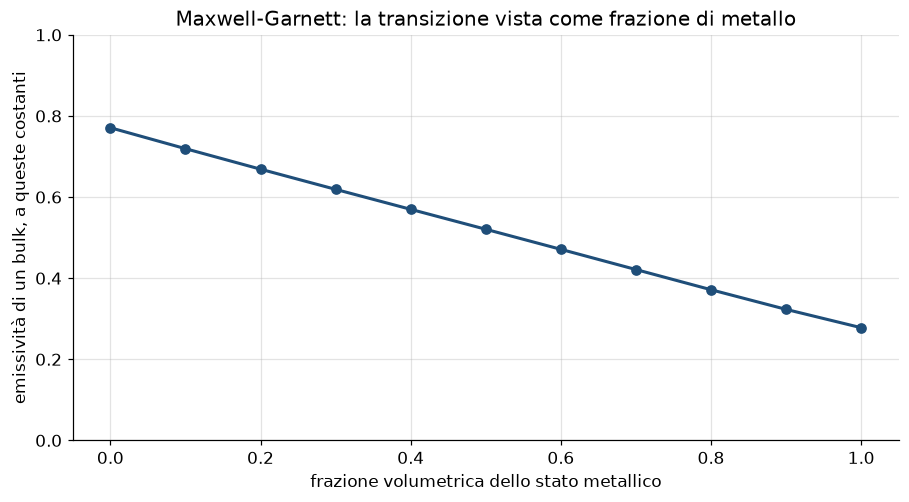

Bulk, f=0 → ε=0.77;  f=1 → ε=0.28


In [6]:
def matrice_strato(n, d, lam):
    """Matrice caratteristica di un film, incidenza normale. n e d in metri la λ."""
    delta = 2 * np.pi * n * d / lam
    return np.array([
        [np.cos(delta), 1j / n * np.sin(delta)],
        [1j * n * np.sin(delta), np.cos(delta)],
    ])

def riflettivita(n_layers, spessori, n_sub, lam, n_in=1.0):
    """R di uno stack. n_layers è una lista di indici, uno per strato."""
    M = np.eye(2, dtype=complex)
    for n, d in zip(n_layers, spessori):
        M = M @ matrice_strato(n, d, lam)
    B = M[0, 0] + M[0, 1] * n_sub
    Cc = M[1, 0] + M[1, 1] * n_sub
    r = (n_in * B - Cc) / (n_in * B + Cc)
    return np.abs(r) ** 2

# Film nullo: si deve ritrovare Fresnel del substrato nudo.
n_al = 8 + 40j
lam0 = 4e-6
R_stack = riflettivita([], [], n_al, lam0)
R_fresnel = np.abs((1 - n_al) / (1 + n_al)) ** 2
assert np.isclose(R_stack, R_fresnel)

n_semi = 2.8 + 0.3j
n_met = 5.0 + 6.0j
d_film = 190e-9
lam = np.linspace(2.5e-6, 12e-6, 500)

R_semi = np.array([riflettivita([n_semi], [d_film], n_al, l) for l in lam])
R_met = np.array([riflettivita([n_met], [d_film], n_al, l) for l in lam])
eps_semi = 1 - R_semi
eps_met = 1 - R_met

fig, ax = plt.subplots()
ax.plot(lam * 1e6, eps_semi, lw=2, label="VO₂ semiconduttore, 190 nm")
ax.plot(lam * 1e6, eps_met, lw=2, label="VO₂ metallico, 190 nm")
ax.fill_between(lam * 1e6, eps_met, eps_semi, color="#f4b183", alpha=0.45, label="tunabilità Δε")
ax.axvspan(3, 5, color="#9dc3e6", alpha=0.25)
ax.axvspan(8, 12, color="#c5e0b4", alpha=0.30)
ax.set_xlabel("lunghezza d'onda (μm)")
ax.set_ylabel("emissività ε = 1 − R")
ax.set_ylim(0, 1)
ax.set_title("Film didattico di VO₂ su alluminio")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


def banda(eps, lam, a, b):
    m = (lam >= a) & (lam <= b)
    return np.trapezoid(eps[m], lam[m]) / (b - a)

print("Emissività media del modello:")
print(f"  3–5 μm   semi {banda(eps_semi, lam, 3e-6, 5e-6):.2f}   metallo {banda(eps_met, lam, 3e-6, 5e-6):.2f}")
print(f"  8–12 μm  semi {banda(eps_semi, lam, 8e-6, 12e-6):.2f}   metallo {banda(eps_met, lam, 8e-6, 12e-6):.2f}")


def maxwell_garnett(eps_i, eps_h, f):
    return eps_h * (eps_i + 2 * eps_h + 2 * f * (eps_i - eps_h)) / (
        eps_i + 2 * eps_h - f * (eps_i - eps_h)
    )

def indice_passivo(eps):
    """Radice con parte immaginaria ≥ 0, convenzione e^{+jωt} assorbente se Im(n)≥0? 
    Per e^{-iωt} il mezzo passivo ha Im(n)≥0. Usiamo la radice con Im≥0."""
    n = np.sqrt(eps + 0j)
    if np.imag(n) < 0:
        n = -n
    return n

f = np.linspace(0, 1, 11)
# A 10 μm, bulk opaco: ε_rad = 1 − R di Fresnel dell'indice efficace.
R_f = []
for fi in f:
    eps_eff = maxwell_garnett(n_met**2, n_semi**2, fi)
    n_eff = indice_passivo(eps_eff)
    R_f.append(np.abs((1 - n_eff) / (1 + n_eff)) ** 2)
R_f = np.array(R_f)

fig, ax = plt.subplots()
ax.plot(f, 1 - R_f, "o-", color="#1f4e79", lw=2)
ax.set_xlabel("frazione volumetrica dello stato metallico")
ax.set_ylabel("emissività di un bulk, a queste costanti")
ax.set_title("Maxwell-Garnett: la transizione vista come frazione di metallo")
ax.set_ylim(0, 1)
fig.tight_layout()
plt.show()
print(f"Bulk, f=0 → ε={1-R_f[0]:.2f};  f=1 → ε={1-R_f[-1]:.2f}")


## 6. Tessuti e polveri bioceramiche

L'altra campagna mostrata a lezione misura l'emissività di tessuti rivestiti
con ossidi. I non rivestiti più emissivi sono cotone-PES e viscosa (0,84).
Il valore più alto della tabella è viscosa con Al₂O₃, 0,93. La legge di
Kirchhoff, controllata in FTIR, resta \(\varepsilon=\alpha\) per questi campioni opachi.

Conto diretto sulla tabella: su 35 confronti trattamento/non rivestito,
31 emissività salgono, 2 restano uguali, 2 scendono. È il «circa il 90%»
della conclusione della lezione.


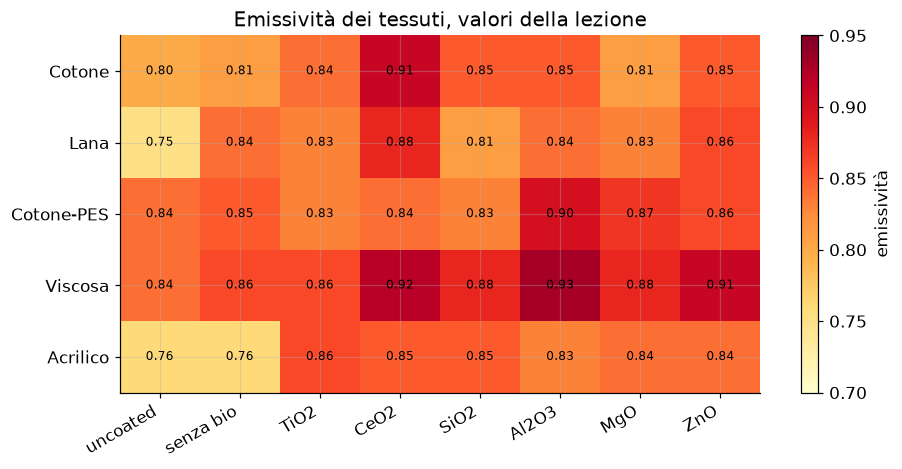

Confronti: 31 in aumento, 2 invariati, 2 in calo, su 35.
Frazione in aumento: 89%
Massimo: Viscosa / Al2O3 = 0.93
Non rivestiti, in ordine: Viscosa 0.84, Cotone-PES 0.84, Cotone 0.80, Acrilico 0.76, Lana 0.75


In [7]:
colonne = ["uncoated", "senza bio", "TiO2", "CeO2", "SiO2", "Al2O3", "MgO", "ZnO"]
tessuti = ["Cotone", "Lana", "Cotone-PES", "Viscosa", "Acrilico"]
dati = np.array([
    [0.80, 0.81, 0.84, 0.91, 0.85, 0.85, 0.81, 0.85],
    [0.75, 0.84, 0.83, 0.88, 0.81, 0.84, 0.83, 0.86],
    [0.84, 0.85, 0.83, 0.84, 0.83, 0.90, 0.87, 0.86],
    [0.84, 0.86, 0.86, 0.92, 0.88, 0.93, 0.88, 0.91],
    [0.76, 0.76, 0.86, 0.85, 0.85, 0.83, 0.84, 0.84],
])

fig, ax = plt.subplots(figsize=(8.6, 4.4))
im = ax.imshow(dati, cmap="YlOrRd", vmin=0.70, vmax=0.95, aspect="auto")
ax.set_xticks(range(len(colonne)), colonne, rotation=30, ha="right")
ax.set_yticks(range(len(tessuti)), tessuti)
for i in range(dati.shape[0]):
    for j in range(dati.shape[1]):
        ax.text(j, i, f"{dati[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="emissività")
ax.set_title("Emissività dei tessuti, valori della lezione")
fig.tight_layout()
plt.show()

base = dati[:, 0:1]
delta = dati[:, 1:] - base
n_su = np.sum(delta > 0)
n_giu = np.sum(delta < 0)
n_uguali = np.sum(np.isclose(delta, 0.0))
print(f"Confronti: {n_su} in aumento, {n_uguali} invariati, {n_giu} in calo, su {delta.size}.")
print(f"Frazione in aumento: {n_su / delta.size:.0%}")
i, j = np.unravel_index(np.argmax(dati), dati.shape)
print(f"Massimo: {tessuti[i]} / {colonne[j]} = {dati[i, j]:.2f}")
non_riv = dati[:, 0]
print("Non rivestiti, in ordine:", ", ".join(
    f"{tessuti[k]} {non_riv[k]:.2f}" for k in np.argsort(non_riv)[::-1]
))


## In sintesi

- Le finestre utili sono la 3–5 μm e la 8–12 μm. A temperatura ambiente il corpo nero vive nella seconda, e lì lavorano i microbolometri non raffreddati.
- Con \(\tau\approx 1\), \(\varepsilon_s=\varepsilon_a(T_a^4-T_\mathrm{amb}^4)/(T_s^4-T_\mathrm{amb}^4)\). Senza il termine riflesso il numero che esce è sbagliato.
- A 50 °C, passare da \(\varepsilon=0{,}9\) a \(\varepsilon=0{,}35\) dimezza abbondantemente il contrasto apparente con un ambiente a 20 °C.
- Nelle polveri di VO₂ della lezione la tunabilità arriva a \(\Delta\varepsilon=-0{,}42\) (D5T5). Nei tessuti, viscosa/Al₂O₃ arriva a 0,93 e circa nove trattamenti su dieci alzano l'emissività.
- Maxwell-Garnett lega la frazione di fase metallica all'emissività del misto. Il film da 190 nm è il caso in cui questa variazione diventa un filtro.
